In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
df = pd.read_csv("insurance.csv")
df.columns = df.columns.str.strip()

print(df.head())
print(df.shape)
print(df.isnull().sum())
print("Duplicates:", df.duplicated().sum())

   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520
(1338, 7)
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64
Duplicates: 1


In [3]:
df = df.drop_duplicates().reset_index(drop=True)

In [4]:
print("Duplicates:", df.duplicated().sum())

Duplicates: 0


In [5]:
X = df.drop("charges", axis=1)
y = df["charges"]

X = pd.get_dummies(
    X,
    columns=["sex", "smoker", "region"],
    drop_first=True,
    dtype=int
)

print(X.head())

   age     bmi  children  sex_male  smoker_yes  region_northwest  \
0   19  27.900         0         0           1                 0   
1   18  33.770         1         1           0                 0   
2   28  33.000         3         1           0                 0   
3   33  22.705         0         1           0                 1   
4   32  28.880         0         1           0                 1   

   region_southeast  region_southwest  
0                 0                 1  
1                 1                 0  
2                 1                 0  
3                 0                 0  
4                 0                 0  


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print(X_train.shape, X_test.shape)

(1069, 8) (268, 8)


In [7]:
model = RandomForestRegressor(
    n_estimators=200,
    max_depth=10,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)
print("Model trained successfully!")

Model trained successfully!


In [8]:
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MAE :", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R2  :", round(r2, 4))
print("R2 %:", round(r2 * 100, 2), "%")

MAE : 3374.73
RMSE: 5222.7
R2  : 0.8516
R2 %: 85.16 %


In [9]:
comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

print(comparison.head(10))

        Actual     Predicted
0   8688.85885  10838.068092
1   5708.86700   7486.972482
2  11436.73815  14682.460399
3  38746.35510  32443.520843
4   4463.20510   6615.944013
5   9304.70190  10708.654850
6  38511.62830  36038.415206
7   2150.46900   3345.863550
8   7345.72660   8894.918382
9  10264.44210  11160.726219


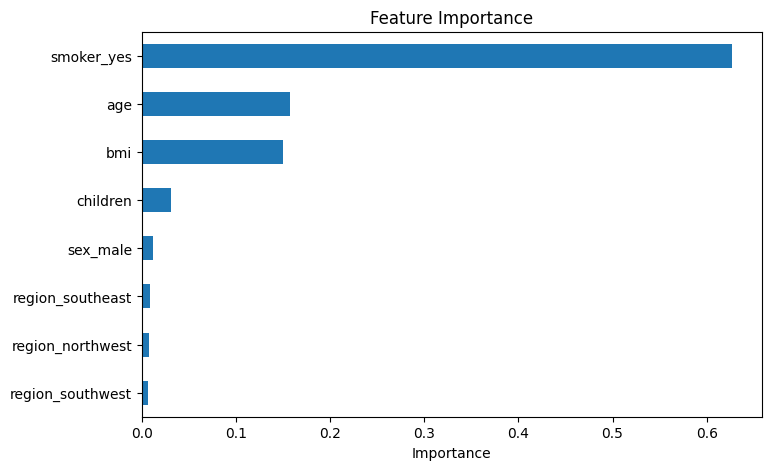

In [10]:
importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=True)

importance.plot(kind="barh", figsize=(8, 5))
plt.title("Feature Importance")
plt.xlabel("Importance")
plt.show()

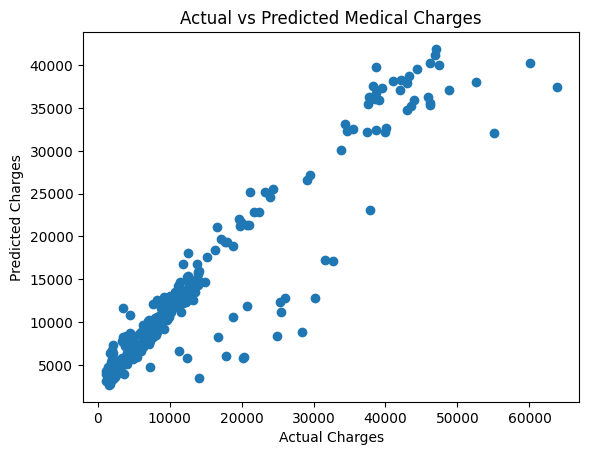

In [11]:
plt.scatter(y_test, y_pred)
plt.xlabel("Actual Charges")
plt.ylabel("Predicted Charges")
plt.title("Actual vs Predicted Medical Charges")
plt.show()

In [13]:
patient = pd.DataFrame({
    "age": [30],
    "sex": ["male"],
    "bmi": [25.5],
    "children": [2],
    "smoker": ["no"],
    "region": ["southeast"]
})

patient = pd.get_dummies(
    patient,
    columns=["sex", "smoker", "region"],
    drop_first=True,
    dtype=int
)

patient = patient.reindex(columns=X.columns, fill_value=0)

prediction = model.predict(patient)[0]

print("Predicted Medical Charges: ", round(prediction, 2))

Predicted Medical Charges:  8380.0
